# IF3070 Foundations of Artificial Intelligence | Tugas Besar 2

Group Number: 22

Group Members:
- Dinda Thalia Fahira (18222055)
- Mohamad Maulana Firdaus Ramadhan (18222140)

## Install Libraries

In [ ]:
!pip install pandas numpy seaborn matplotlib scipy scikit-learn joblib

## Import Libraries

In [1]:
import warnings
warnings.filterwarnings('ignore')

import re
from typing import List

import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import skew
import math
from sklearn.impute import SimpleImputer

from urllib.parse import urlparse

from sklearn.model_selection import (
    train_test_split, GridSearchCV,
)
from sklearn.metrics import (
    accuracy_score, roc_auc_score, confusion_matrix, f1_score, classification_report, recall_score, precision_score, ConfusionMatrixDisplay, make_scorer
)
from sklearn.preprocessing import (
    MinMaxScaler, StandardScaler, LabelEncoder, FunctionTransformer, 
    PowerTransformer, PolynomialFeatures, RobustScaler
)
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.base import BaseEstimator, TransformerMixin

from sklearn.decomposition import PCA

import joblib

sns.set()
plt.style.use('ggplot')
pd.set_option('display.max_columns', None)

## Import Dataset

In [2]:
df_train = pd.read_csv('data/train.csv')
df_test = pd.read_csv('data/test.csv')
sample_submission = pd.read_csv('data/sample_submission.csv')

In [3]:
df_train.head(20)

,id,FILENAME,URL,URLLength,Domain,DomainLength,IsDomainIP,TLD,CharContinuationRate,TLDLegitimateProb,URLCharProb,TLDLength,NoOfSubDomain,HasObfuscation,NoOfObfuscatedChar,ObfuscationRatio,NoOfLettersInURL,LetterRatioInURL,NoOfDegitsInURL,DegitRatioInURL,NoOfEqualsInURL,NoOfQMarkInURL,NoOfAmpersandInURL,NoOfOtherSpecialCharsInURL,SpacialCharRatioInURL,IsHTTPS,LineOfCode,LargestLineLength,HasTitle,Title,DomainTitleMatchScore,URLTitleMatchScore,HasFavicon,Robots,IsResponsive,NoOfURLRedirect,NoOfSelfRedirect,HasDescription,NoOfPopup,NoOfiFrame,HasExternalFormSubmit,HasSocialNet,HasSubmitButton,HasHiddenFields,HasPasswordField,Bank,Pay,Crypto,HasCopyrightInfo,NoOfImage,NoOfCSS,NoOfJS,NoOfSelfRef,NoOfEmptyRef,NoOfExternalRef,label
0,1,NaN,https://www.northcm.ac.th,24.0,www.northcm.ac.th,17.0,0.0,NaN,0.800000,NaN,NaN,NaN,2.0,0.0,NaN,0.0,NaN,0.417,0.0,0.000,0.0,0.0,0.0,2.0,0.083,NaN,NaN,457.0,NaN,norhcmac,NaN,NaN,NaN,0.0,NaN,NaN,0.0,NaN,0.0,5.0,0.0,NaN,NaN,NaN,0.0,NaN,0.0,0.0,1.0,NaN,3.0,NaN,69.0,NaN,NaN,1
1,4,8135291.txt,http://uqr.to/1il1z,NaN,NaN,NaN,NaN,to,1.000000,0.000896,0.036850,2.0,0.0,NaN,0.0,NaN,8.0,0.421,2.0,0.105,NaN,NaN,0.0,2.0,NaN,NaN,9.0,NaN,1.0,NaN,NaN,100.000000,0.0,NaN,NaN,0.0,0.0,NaN,0.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.0,NaN,NaN,NaN,NaN,NaN,1.0,0
2,5,586561.txt,https://www.woolworthsrewards.com.au,35.0,www.woolworthsrewards.com.au,28.0,0.0,au,0.857143,NaN,0.060894,NaN,2.0,NaN,NaN,0.0,NaN,NaN,0.0,NaN,0.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,1.0,woolworthsrewrdscom,0.0,0.000000,1.0,0.0,1.0,NaN,1.0,NaN,0.0,3.0,0.0,NaN,NaN,1.0,1.0,1.0,1.0,0.0,1.0,33.0,7.0,8.0,15.0,NaN,2.0,1
3,6,NaN,NaN,31.0,NaN,NaN,NaN,com,0.562500,0.522907,0.055829,NaN,1.0,NaN,0.0,NaN,17.0,NaN,0.0,0.000,NaN,0.0,0.0,NaN,0.065,NaN,NaN,5062.0,NaN,NaN,100.0,100.000000,NaN,0.0,NaN,0.0,0.0,0.0,7.0,NaN,NaN,NaN,NaN,NaN,NaN,0.0,1.0,0.0,1.0,24.0,5.0,14.0,NaN,NaN,NaN,1
4,11,412632.txt,NaN,NaN,www.nyprowrestling.com,22.0,0.0,NaN,1.000000,NaN,NaN,NaN,1.0,NaN,NaN,0.0,NaN,NaN,0.0,0.000,NaN,0.0,NaN,1.0,0.034,1.0,766.0,NaN,NaN,nyprowrestling,100.0,100.000000,1.0,1.0,NaN,0.0,NaN,1.0,0.0,0.0,NaN,1.0,NaN,0.0,0.0,0.0,0.0,0.0,1.0,NaN,NaN,14.0,NaN,0.0,NaN,1
5,12,899992.txt,https://www.free-marine.com,26.0,NaN,19.0,NaN,com,0.636364,NaN,0.070574,3.0,1.0,0.0,NaN,0.0,NaN,NaN,0.0,NaN,0.0,0.0,0.0,NaN,0.077,NaN,240.0,NaN,1.0,NaN,100.0,100.000000,NaN,NaN,1.0,0.0,NaN,1.0,0.0,NaN,NaN,NaN,1.0,0.0,0.0,NaN,NaN,0.0,0.0,15.0,3.0,2.0,4.0,1.0,NaN,1
6,17,NaN,https://www.ridemcts.com,23.0,www.ridemcts.com,16.0,0.0,com,NaN,0.522907,NaN,3.0,1.0,NaN,NaN,0.0,10.0,0.435,NaN,0.000,NaN,0.0,NaN,1.0,NaN,1.0,NaN,NaN,1.0,NaN,100.0,100.000000,0.0,0.0,1.0,NaN,0.0,0.0,0.0,NaN,NaN,1.0,NaN,1.0,0.0,NaN,1.0,0.0,1.0,NaN,NaN,22.0,NaN,4.0,8.0,1
7,19,568276.txt,https://www.epner.com,NaN,NaN,NaN,0.0,com,NaN,0.522907,0.071276,3.0,NaN,0.0,NaN,NaN,NaN,NaN,0.0,0.000,NaN,NaN,0.0,NaN,0.050,1.0,1266.0,9381.0,1.0,epner,100.0,100.000000,1.0,NaN,1.0,NaN,0.0,0.0,0.0,0.0,NaN,1.0,NaN,1.0,NaN,NaN,NaN,0.0,NaN,40.0,NaN,19.0,176.0,NaN,144.0,1
8,20,52998.txt,https://www.az511.com,NaN,www.az511.com,13.0,0.0,com,1.000000,NaN,0.038131,3.0,NaN,0.0,0.0,NaN,NaN,NaN,3.0,0.150,0.0,NaN,0.0,1.0,0.050,NaN,NaN,1080.0,NaN,az511,NaN,100.000000,1.0,0.0,NaN,0.0,0.0,1.0,0.0,NaN,0.0,NaN,NaN,1.0,NaN,NaN,NaN,NaN,0.0,NaN,33.0,9.0,109.0,7.0,NaN,1
9,22,NaN,https://www.screenbeam.com,25.0,www.screenbeam.com,18.0,NaN,NaN,1.000000,0.522907,NaN,3.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.000,NaN,NaN,0.0,1.0,0.040,1.0,2433.0,NaN,1.0,screenbeam,100.0,100.000000,NaN,NaN,1.0,NaN,NaN,1.0,2.0,5.0,0.0,NaN,1.0,1.0,0.0,0.0,NaN,NaN,NaN,NaN,27.0,48.0,148.0,11.0,NaN,1


## Exploratory Data Analysis

In [4]:
df_train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 140404 entries, 0 to 140403
Data columns (total 56 columns):
 #   Column                      Non-Null Count   Dtype  
---  ------                      --------------   -----  
 0   id                          140404 non-null  int64  
 1   FILENAME                    82872 non-null   object 
 2   URL                         96917 non-null   object 
 3   URLLength                   79765 non-null   float64
 4   Domain                      70207 non-null   object 
 5   DomainLength                94085 non-null   float64
 6   IsDomainIP                  98274 non-null   float64
 7   TLD                         95005 non-null   object 
 8   CharContinuationRate        92362 non-null   float64
 9   TLDLegitimateProb           87531 non-null   float64
 10  URLCharProb                 88333 non-null   float64
 11  TLDLength                   92673 non-null   float64
 12  NoOfSubDomain               96344 non-null   float64
 13  HasObfuscation

In [5]:
df_train.columns

Index(['id', 'FILENAME', 'URL', 'URLLength', 'Domain', 'DomainLength',
       'IsDomainIP', 'TLD', 'CharContinuationRate', 'TLDLegitimateProb',
       'URLCharProb', 'TLDLength', 'NoOfSubDomain', 'HasObfuscation',
       'NoOfObfuscatedChar', 'ObfuscationRatio', 'NoOfLettersInURL',
       'LetterRatioInURL', 'NoOfDegitsInURL', 'DegitRatioInURL',
       'NoOfEqualsInURL', 'NoOfQMarkInURL', 'NoOfAmpersandInURL',
       'NoOfOtherSpecialCharsInURL', 'SpacialCharRatioInURL', 'IsHTTPS',
       'LineOfCode', 'LargestLineLength', 'HasTitle', 'Title',
       'DomainTitleMatchScore', 'URLTitleMatchScore', 'HasFavicon', 'Robots',
       'IsResponsive', 'NoOfURLRedirect', 'NoOfSelfRedirect', 'HasDescription',
       'NoOfPopup', 'NoOfiFrame', 'HasExternalFormSubmit', 'HasSocialNet',
       'HasSubmitButton', 'HasHiddenFields', 'HasPasswordField', 'Bank', 'Pay',
       'Crypto', 'HasCopyrightInfo', 'NoOfImage', 'NoOfCSS', 'NoOfJS',
       'NoOfSelfRef', 'NoOfEmptyRef', 'NoOfExternalRef', 'label'],

In [20]:
df_train.duplicated().sum()

0

In [6]:
df_train.isnull().sum().sort_values(ascending=False)

Domain                        70197
NoOfExternalRef               69379
LineOfCode                    69153
HasSocialNet                  67999
LargestLineLength             67928
NoOfURLRedirect               67384
HasCopyrightInfo              67345
NoOfCSS                       67134
NoOfObfuscatedChar            66798
NoOfSelfRedirect              66715
HasPasswordField              66535
LetterRatioInURL              65746
HasObfuscation                65720
ObfuscationRatio              64598
NoOfLettersInURL              63338
SpacialCharRatioInURL         62834
HasSubmitButton               61620
NoOfEqualsInURL               61578
NoOfJS                        60801
URLLength                     60639
NoOfDegitsInURL               58810
HasFavicon                    58422
Title                         58247
FILENAME                      57532
HasExternalFormSubmit         55592
Bank                          54996
HasDescription                54639
DegitRatioInURL             

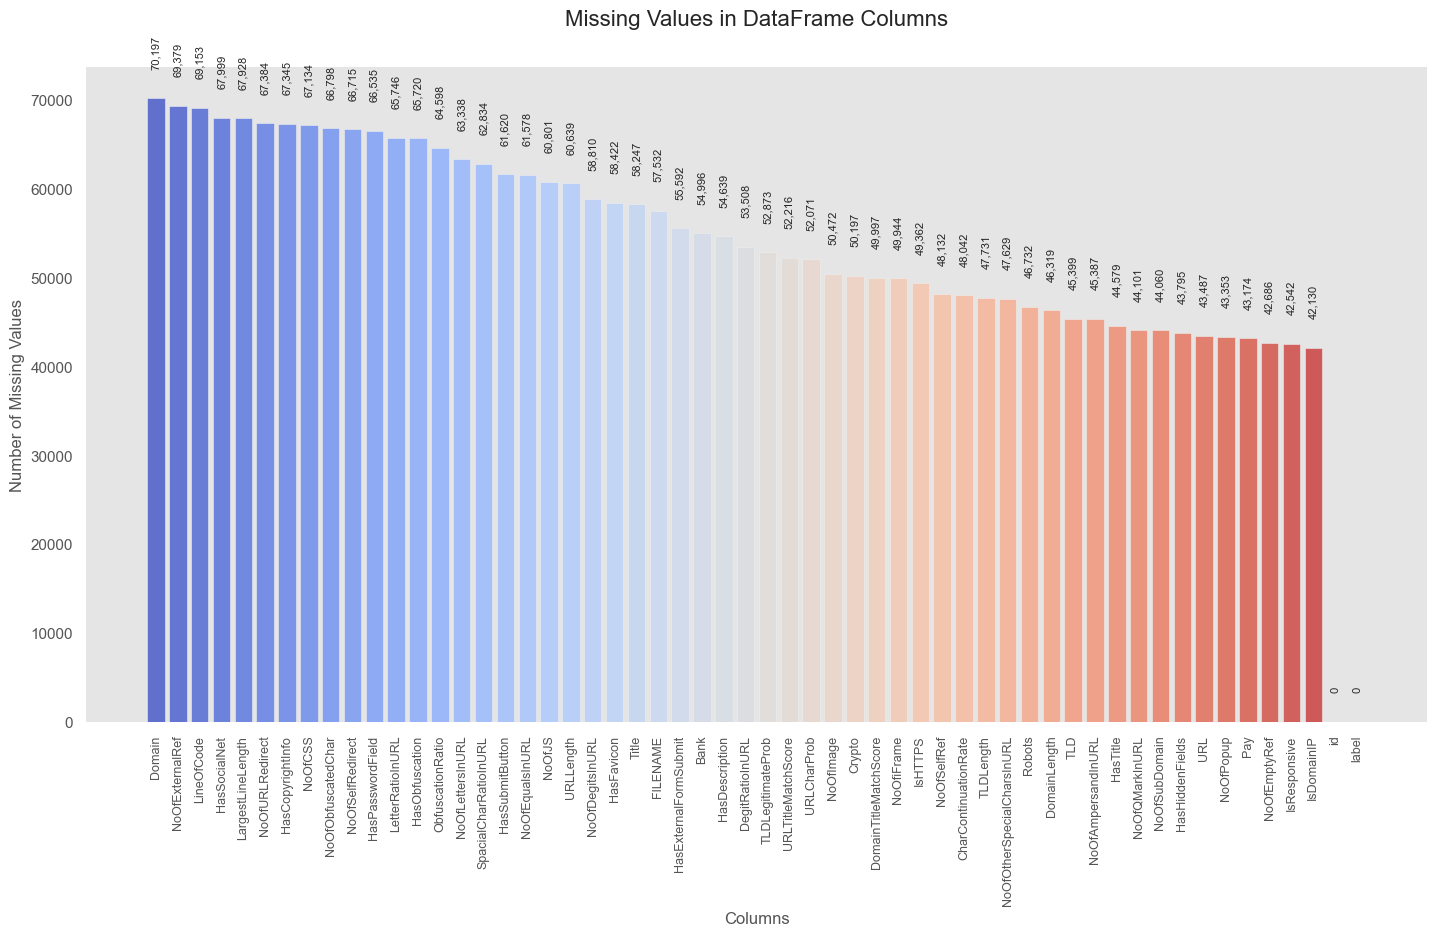

In [7]:
# Missing Values
missing_values = df_train.isnull().sum()
missing_values = pd.DataFrame({'Column': missing_values.index, 'Missing Values': missing_values.values})
missing_values.sort_values(by='Missing Values', ascending=False, inplace=True)
missing_values.reset_index(drop=True, inplace=True)

# Sort by 'Missing Values'
missing_values = missing_values.sort_values(by='Missing Values', ascending=False).reset_index(drop=True)

# Set a gradient color palette
colors = sns.color_palette("coolwarm", len(missing_values))

# Plot for missing values
plt.figure(figsize=(15, 10))
bars = plt.bar(missing_values['Column'], missing_values['Missing Values'], color=colors, alpha=0.8)

# Add numbers above bars
for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + (70197 * 0.05),
        f'{bar.get_height():,}',
        ha='center',
        fontsize=8,
        rotation=90
    )

# Remove gridlines and spines
plt.grid(False)
for spine in plt.gca().spines.values():
    spine.set_visible(False)

# Labels and title
plt.xlabel('Columns', fontsize=12)
plt.ylabel('Number of Missing Values', fontsize=12)
plt.title('Missing Values in DataFrame Columns', fontsize=16, pad=30)
plt.xticks(rotation=90, fontsize=9)

# Adjust the layout
plt.tight_layout(pad=3.0)
plt.show()

In [8]:
for col in df_train.columns:
    print(f'{col}: {df_train[col].nunique()}')

id: 140404
FILENAME: 82872
URL: 96914
URLLength: 215
Domain: 69832
DomainLength: 80
IsDomainIP: 2
TLD: 497
CharContinuationRate: 463
TLDLegitimateProb: 410
URLCharProb: 87625
TLDLength: 11
NoOfSubDomain: 8
HasObfuscation: 2
NoOfObfuscatedChar: 8
ObfuscationRatio: 26
NoOfLettersInURL: 193
LetterRatioInURL: 500
NoOfDegitsInURL: 82
DegitRatioInURL: 378
NoOfEqualsInURL: 14
NoOfQMarkInURL: 4
NoOfAmpersandInURL: 16
NoOfOtherSpecialCharsInURL: 44
SpacialCharRatioInURL: 177
IsHTTPS: 2
LineOfCode: 8311
LargestLineLength: 17076
HasTitle: 2
Title: 79460
DomainTitleMatchScore: 107
URLTitleMatchScore: 197
HasFavicon: 2
Robots: 2
IsResponsive: 2
NoOfURLRedirect: 2
NoOfSelfRedirect: 2
HasDescription: 2
NoOfPopup: 104
NoOfiFrame: 99
HasExternalFormSubmit: 2
HasSocialNet: 2
HasSubmitButton: 2
HasHiddenFields: 2
HasPasswordField: 2
Bank: 2
Pay: 2
Crypto: 2
HasCopyrightInfo: 2
NoOfImage: 819
NoOfCSS: 178
NoOfJS: 215
NoOfSelfRef: 1185
NoOfEmptyRef: 255
NoOfExternalRef: 951
label: 2


In [8]:
LABEL = 'label'

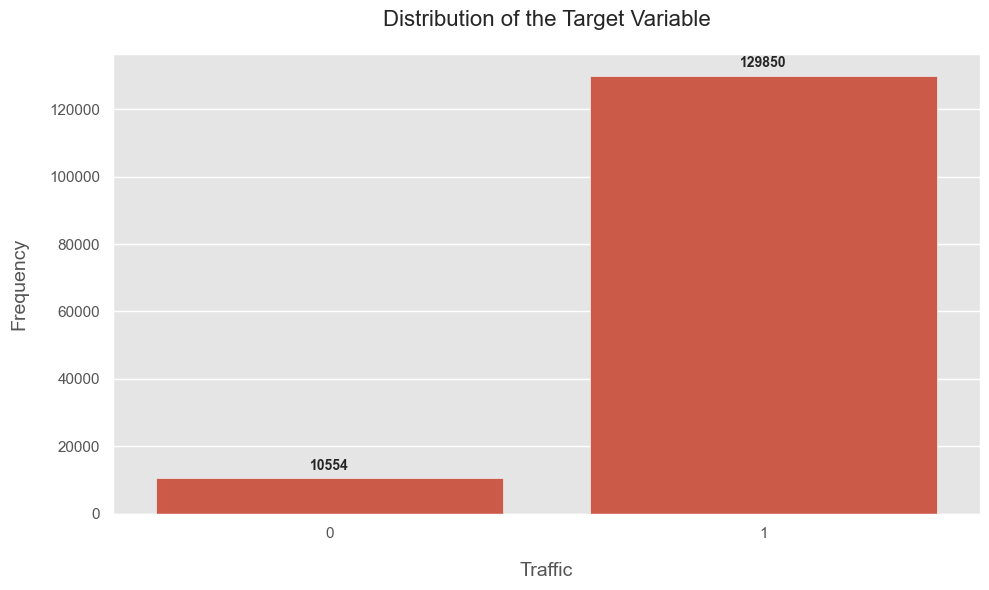

In [10]:
# Set up the figure size and palette
plt.figure(figsize=(10, 6))

# Create the countplot
count_plot = sns.countplot(data=df_train, x=LABEL)

# Add title and labels
plt.title('Distribution of the Target Variable', fontsize=16, pad=20)
plt.xlabel('Traffic', fontsize=14, labelpad=15)
plt.ylabel('Frequency', fontsize=14, labelpad=15)

# Add the count numbers on top of each bar
for p in count_plot.patches:
    count_plot.annotate(f'{int(p.get_height())}', 
                        (p.get_x() + p.get_width() / 2., p.get_height()), 
                        ha = 'center', va = 'center', 
                        xytext = (0, 9), 
                        textcoords = 'offset points', 
                        fontweight='bold')

# Show the plot
plt.tight_layout()
plt.show()

In [11]:
phising_data = df_train[df_train[LABEL] == 1]
normal_data = df_train[df_train[LABEL] == 0]

In [12]:
phising_data.describe()

,id,URLLength,DomainLength,IsDomainIP,CharContinuationRate,TLDLegitimateProb,URLCharProb,TLDLength,NoOfSubDomain,HasObfuscation,NoOfObfuscatedChar,ObfuscationRatio,NoOfLettersInURL,LetterRatioInURL,NoOfDegitsInURL,DegitRatioInURL,NoOfEqualsInURL,NoOfQMarkInURL,NoOfAmpersandInURL,NoOfOtherSpecialCharsInURL,SpacialCharRatioInURL,IsHTTPS,LineOfCode,LargestLineLength,HasTitle,DomainTitleMatchScore,URLTitleMatchScore,HasFavicon,Robots,IsResponsive,NoOfURLRedirect,NoOfSelfRedirect,HasDescription,NoOfPopup,NoOfiFrame,HasExternalFormSubmit,HasSocialNet,HasSubmitButton,HasHiddenFields,HasPasswordField,Bank,Pay,Crypto,HasCopyrightInfo,NoOfImage,NoOfCSS,NoOfJS,NoOfSelfRef,NoOfEmptyRef,NoOfExternalRef,label
count,129850.000000,73706.000000,86997.000000,90938.0,85384.000000,8.096700e+04,81853.000000,85735.000000,89043.000000,68982.0,68059.0,69998.0,71270.000000,69020.000000,75460.000000,80361.000000,72861.0,89023.0,87845.0,85807.000000,71767.000000,84214.0,65934.000000,67015.000000,88662.000000,83616.000000,81612.000000,75758.000000,86562.000000,90541.000000,67544.000000,68195.000000,79438.000000,89716.000000,83698.000000,78441.000000,66921.000000,72876.000000,89380.000000,68330.000000,78953.000000,89931.000000,83434.000000,67575.00000,83139.000000,67805.000000,73571.000000,85337.000000,90364.000000,65702.000000,129850.0
mean,117712.327216,26.227241,19.237089,0.0,0.933614,2.816564e-01,0.060024,2.722564,1.160529,0.0,0.0,0.0,12.949319,0.476611,0.049311,0.002049,0.0,0.0,0.0,1.244141,0.048338,1.0,1936.803698,7423.666522,0.998793,75.248969,75.193220,0.568428,0.416603,0.853536,0.119611,0.026893,0.736675,0.388526,2.704533,0.073928,0.795057,0.659133,0.589517,0.138665,0.182235,0.369016,0.036832,0.80774,44.977868,11.064568,17.739381,113.358121,4.025165,84.337478,1.0
std,68091.426220,4.813077,4.813585,0.0,0.139197,2.471597e-01,0.007207,0.517915,0.401970,0.0,0.0,0.0,4.784774,0.095252,0.345192,0.014377,0.0,0.0,0.0,0.503658,0.018998,0.0,3887.631974,13004.907104,0.034719,42.705747,42.731935,0.495299,0.492999,0.353573,0.324508,0.161773,0.440440,4.978993,8.092073,0.261656,0.403663,0.474004,0.491924,0.345599,0.386041,0.482541,0.188349,0.39408,105.949319,138.559429,21.322659,225.754955,25.130241,193.198483,0.0
min,1.000000,16.000000,8.000000,0.0,0.000000,6.000000e-07,0.002259,2.000000,1.000000,0.0,0.0,0.0,1.000000,0.056000,0.000000,0.000000,0.0,0.0,0.0,0.000000,0.000000,1.0,102.000000,88.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.0
25%,58767.250000,23.000000,16.000000,0.0,1.000000,1.801320e-02,0.056229,2.000000,1.000000,0.0,0.0,0.0,9.000000,0.409000,0.000000,0.000000,0.0,0.0,0.0,1.000000,0.036000,1.0,614.000000,876.500000,1.000000,77.777778,75.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.00000,13.000000,3.000000,8.000000,35.000000,0.000000,17.000000,1.0
50%,117484.000000,26.000000,19.000000,0.0,1.000000,5.229071e-01,0.060638,3.000000,1.000000,0.0,0.0,0.0,13.000000,0.480000,0.000000,0.000000,0.0,0.0,0.0,1.000000,0.042000,1.0,1110.000000,3109.000000,1.000000,100.000000,100.000000,1.000000,0.000000,1.000000,0.000000,0.000000,1.000000,0.000000,1.000000,0.000000,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.00000,25.000000,6.000000,14.000000,76.000000,1.000000,45.000000,1.0
75%,176666.500000,29.000000,22.000000,0.0,1.000000,5.229071e-01,0.064648,3.000000,1.000000,0.0,0.0,0.0,16.000000,0.552000,0.000000,0.000000,0.0,0.0,0.0,1.000000,0.053000,1.0,2088.000000,9381.000000,1.000000,100.000000,100.000000,1.000000,1.000000,1.000000,0.000000,0.000000,1.000000,0.000000,2.000000,0.000000,1.000000,1.000000,1.000000,0.000000,0.000000,1.000000,0.000000,1.00000,47.000000,13.000000,23.000000,139.000000,3.000000,105.000000,1.0
max,235795.000000,57.000000,50.0

In [13]:
for col in df_train.columns:
    print(f'{col}: {phising_data[col].value_counts()}')

id: id
1         1
156919    1
156945    1
156943    1
156942    1
         ..
78369     1
78358     1
78357     1
78356     1
235795    1
Name: count, Length: 129850, dtype: int64
FILENAME: FILENAME
586561.txt    1
600764.txt    1
420332.txt    1
151532.txt    1
35047.txt     1
             ..
381849.txt    1
233883.txt    1
572293.txt    1
503750.txt    1
464776.txt    1
Name: count, Length: 76600, dtype: int64
URL: URL
https://www.northcm.ac.th              1
https://www.umcomo.com.br              1
https://www.moranch.org                1
https://www.vikingrivercruises.com     1
https://www.prettyquirkypants.com      1
                                      ..
https://www.privacyaffairs.com         1
https://www.epiruspost.gr              1
https://www.middlebergnutrition.com    1
https://www.artformurban.co.uk         1
https://www.risenenergy.com            1
Name: count, Length: 89672, dtype: int64
URLLength: URLLength
25.0    6156
24.0    5995
26.0    5854
27.0    5651
23.0    5

In [14]:
normal_data.describe()

,id,URLLength,DomainLength,IsDomainIP,CharContinuationRate,TLDLegitimateProb,URLCharProb,TLDLength,NoOfSubDomain,HasObfuscation,NoOfObfuscatedChar,ObfuscationRatio,NoOfLettersInURL,LetterRatioInURL,NoOfDegitsInURL,DegitRatioInURL,NoOfEqualsInURL,NoOfQMarkInURL,NoOfAmpersandInURL,NoOfOtherSpecialCharsInURL,SpacialCharRatioInURL,IsHTTPS,LineOfCode,LargestLineLength,HasTitle,DomainTitleMatchScore,URLTitleMatchScore,HasFavicon,Robots,IsResponsive,NoOfURLRedirect,NoOfSelfRedirect,HasDescription,NoOfPopup,NoOfiFrame,HasExternalFormSubmit,HasSocialNet,HasSubmitButton,HasHiddenFields,HasPasswordField,Bank,Pay,Crypto,HasCopyrightInfo,NoOfImage,NoOfCSS,NoOfJS,NoOfSelfRef,NoOfEmptyRef,NoOfExternalRef,label
count,10554.000000,6059.000000,7088.000000,7336.000000,6978.000000,6564.000000,6480.000000,6938.000000,7301.000000,5702.000000,5547.000000,5808.000000,5796.000000,5638.000000,6134.000000,6535.000000,5965.000000,7280.000000,7172.000000,6968.000000,5803.000000,6828.000000,5317.000000,5.461000e+03,7163.000000,6791.000000,6576.000000,6224.000000,7110.000000,7321.000000,5476.000000,5494.000000,6327.000000,7335.000000,6762.000000,6371.000000,5484.000000,5908.000000,7229.000000,5539.000000,6455.000000,7299.000000,6773.000000,5484.000000,6793.000000,5465.000000,6032.000000,6935.000000,7354.000000,5323.000000,10554.0
mean,117317.290032,45.635088,24.311653,0.006543,0.727041,0.225990,0.049961,2.808735,1.172579,0.005261,0.078962,0.000363,28.584023,0.565176,4.125367,0.062683,0.135289,0.064835,0.046012,3.763347,0.083314,0.489895,63.061501,1.883441e+04,0.681279,16.458824,20.754465,0.082262,0.062307,0.313482,0.147188,0.051875,0.046468,0.007771,0.077048,0.004552,0.003100,0.084800,0.088256,0.055064,0.052363,0.058501,0.005168,0.059081,0.887237,0.393230,0.878481,0.499928,0.154202,1.167575,0.0
std,68499.300467,80.129282,11.981987,0.080630,0.242268,0.254055,0.011676,0.691094,0.801928,0.072350,3.944152,0.006122,53.447982,0.137223,11.652383,0.093149,0.873622,0.283589,0.876634,6.741051,0.035307,0.499934,150.526296,2.688484e+05,0.466013,36.782819,40.191252,0.274786,0.241729,0.463940,0.354325,0.221794,0.210512,0.133423,0.449960,0.067319,0.055596,0.278608,0.283686,0.228126,0.222774,0.234705,0.071705,0.235798,3.792459,1.073604,3.522294,3.448616,1.751653,4.036067,0.0
min,4.000000,14.000000,4.000000,0.000000,0.142857,0.000000,0.001229,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.010000,0.000000,2.000000,2.300000e+01,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0
25%,57747.750000,25.000000,16.000000,0.000000,0.545455,0.001502,0.042032,2.000000,1.000000,0.000000,0.000000,0.000000,13.000000,0.478000,0.000000,0.000000,0.000000,0.000000,0.000000,2.000000,0.053000,0.000000,2.000000,6.000000e+01,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0
50%,116770.500000,33.000000,22.000000,0.000000,0.719375,0.018013,0.051948,3.000000,1.000000,0.000000,0.000000,0.000000,20.000000,0.571000,0.000000,0.000000,0.000000,0.000000,0.000000,3.000000,0.080000,0.000000,12.000000,1.300000e+02,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0
75%,177478.500000,47.000000,29.000000,0.000000,1.000000,0.522907,0.058633,3.000000,1.000000,0.000000,0.000000,0.000000,31.000000,0.674000,5.000000,0.100000,0.000000,0.000000,0.000000,5.000000,0.111000,1.000000,88.000000,8.560000e+02,1.000000,0.000000,0.970874,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000

In [15]:
for col in df_train.columns:
    print(f'{col}: {normal_data[col].value_counts()}')

id: id
4         1
157153    1
157192    1
157203    1
157214    1
         ..
77003     1
77060     1
77088     1
77184     1
235758    1
Name: count, Length: 10554, dtype: int64
FILENAME: FILENAME
8135291.txt     1
8107067.txt     1
8051216.txt     1
8093266.txt     1
8023470.txt     1
               ..
8104951.txt     1
8132013.txt     1
8059484.txt     1
8095597.txt     1
mw156481.txt    1
Name: count, Length: 6272, dtype: int64
URL: URL
http://test-mantenimiento-bancaweb.azurewebsites.net/      2
https://bmsgadmin.com/admin/index.php                      2
http://www.strangled.net                                   2
https://receipt-b128d.firebaseapp.com/                     1
https://semana-do-consumidor-23-03-2023.myshopify.com/     1
                                                          ..
https://7b782fb2-357c-4184-887a-a4f04a104517.id.repl.co    1
http://www.mail9.blocktrail.com                            1
http://www.wasnrizhgo082vo6w.igmxw.com                     1
https

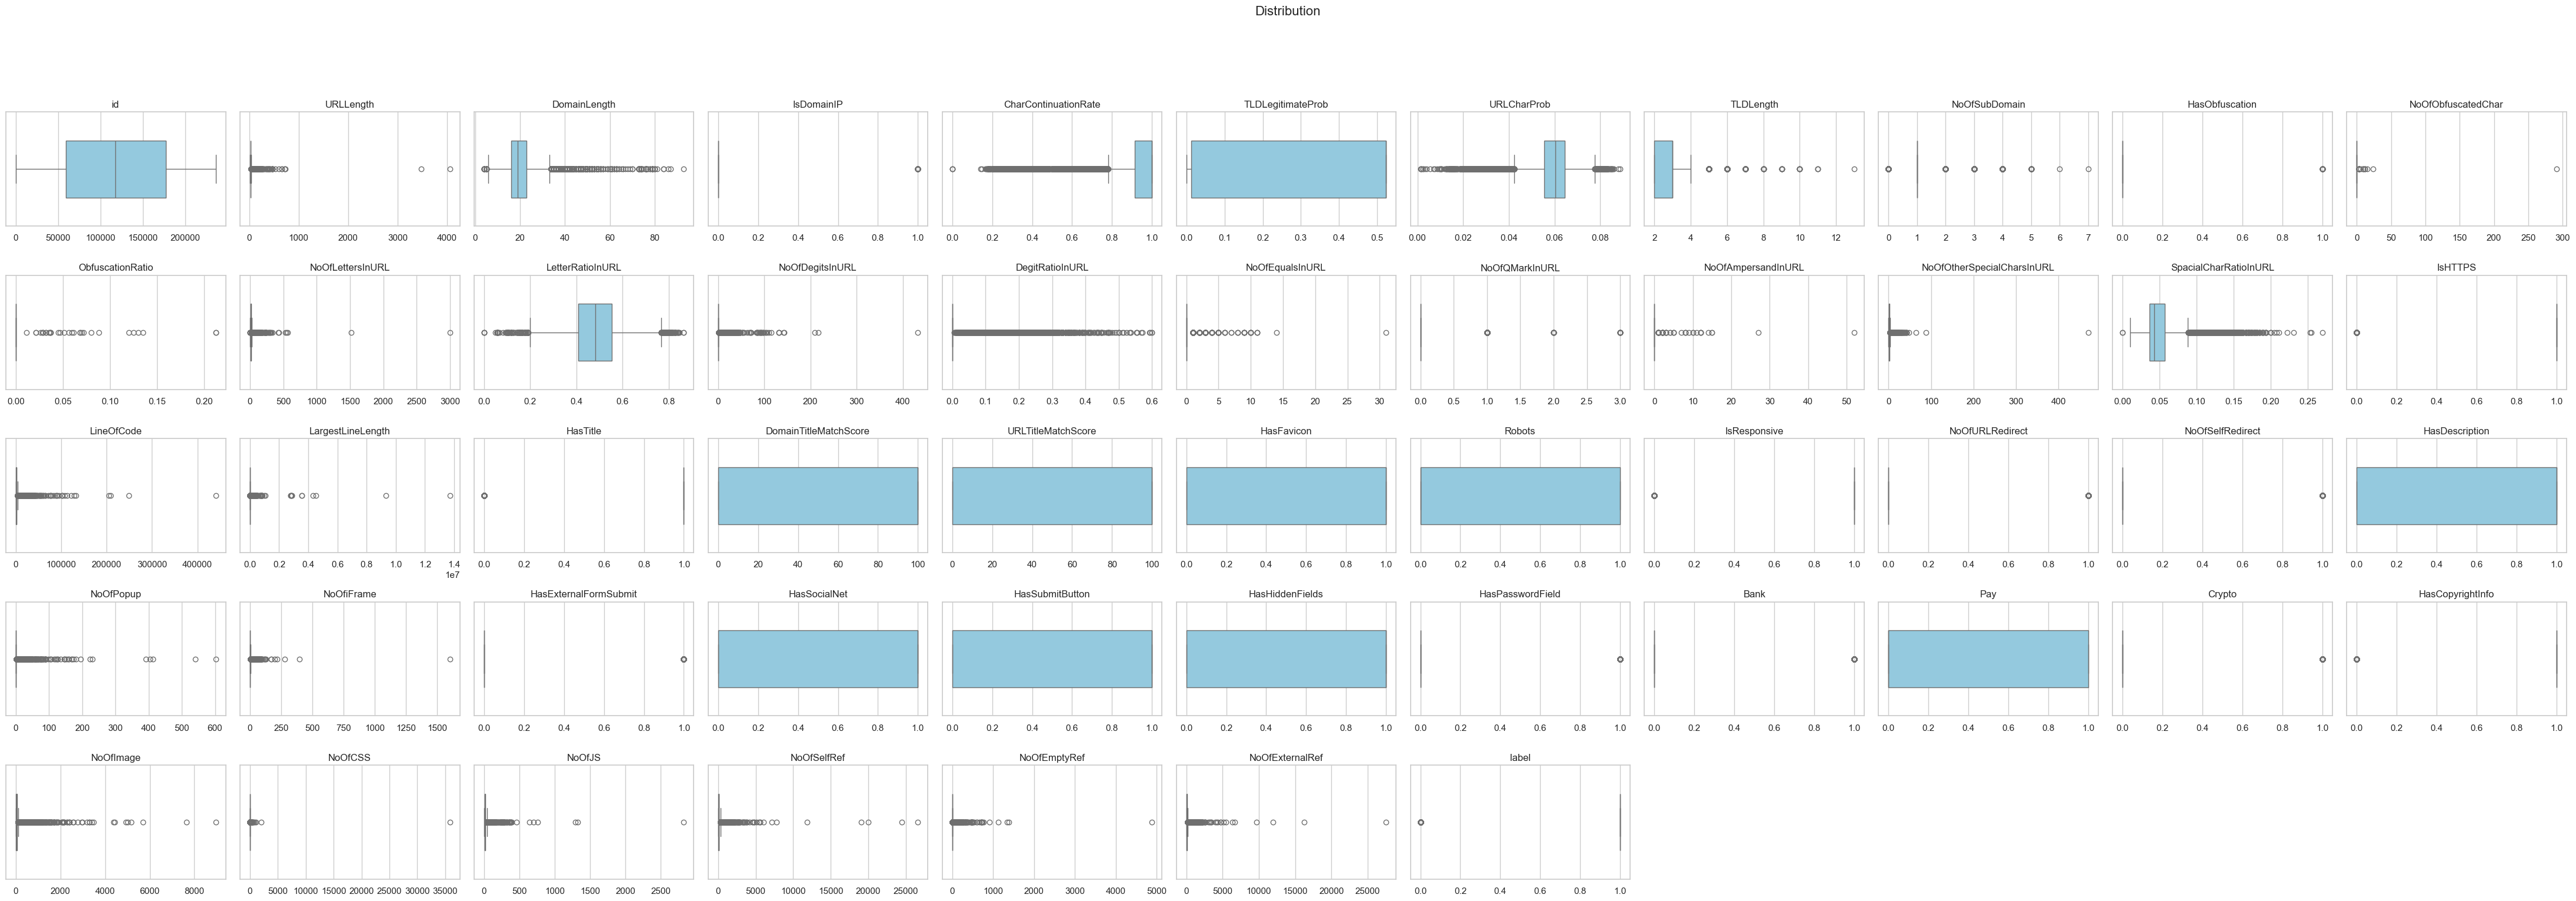

In [16]:
numerical_columns = df_train.select_dtypes(include='number').columns

# Number of numerical columns
num_columns = len(numerical_columns)

# Calculate the number of rows and columns needed for the subplots
num_cols = 11  # Fixed number of columns
num_rows = math.ceil(num_columns / num_cols)  # Calculate rows needed

plt.figure(figsize=(num_cols * 4, num_rows * 3))

sns.set_palette("husl")
sns.set(style="whitegrid")

for i, col in enumerate(numerical_columns, 1):
    plt.subplot(num_rows, num_cols, i)
    sns.boxplot(x=df_train[col], color='skyblue', width=0.5)    
    plt.title(col)
    plt.xlabel("")

plt.suptitle("Distribution", y=1.02, fontsize=16)
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

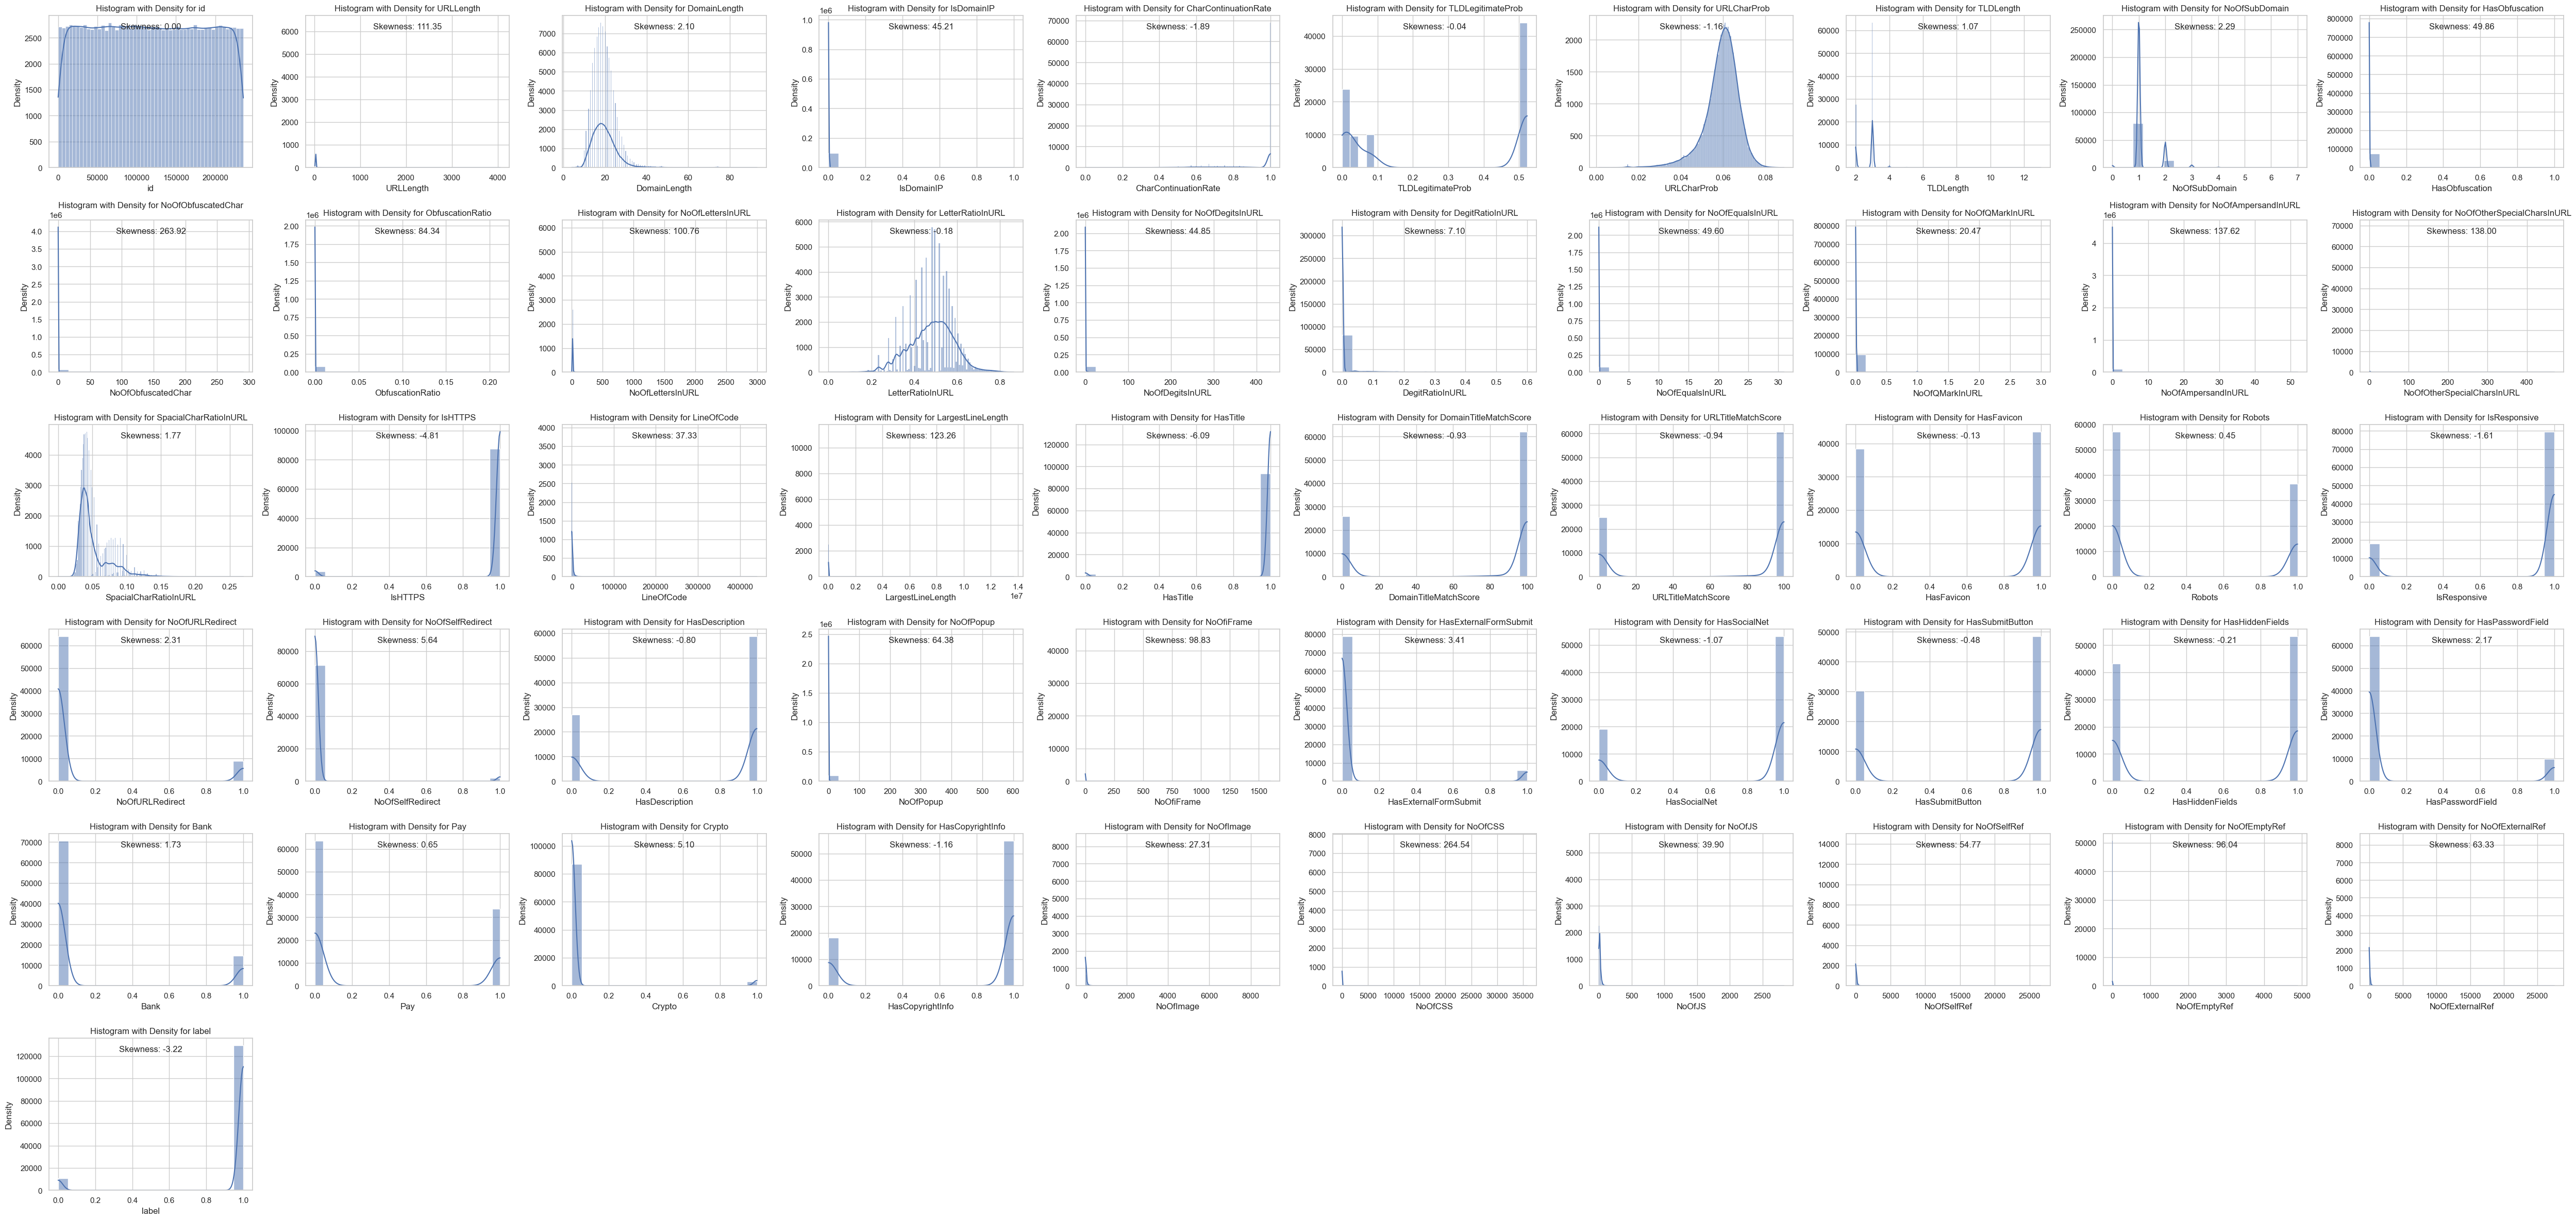

In [17]:
# Select numerical features
numerical_features = df_train.select_dtypes(include=['number']).columns
num_features = len(numerical_features)

# Calculate the number of rows and columns for subplots
num_cols = 10  # Number of columns per row
num_rows = (num_features + num_cols - 1) // num_cols  # Ceiling division to get number of rows
fig, axes = plt.subplots(nrows=num_rows, ncols=num_cols, figsize=(num_cols * 5, 4 * num_rows))

# Flatten axes for easy iteration
axes = axes.flatten()

# Loop through features and create histograms
for i, col in enumerate(numerical_features):
    if col in df_train.columns:
        sns.histplot(data=df_train, x=col, kde=True, ax=axes[i])
        axes[i].set_title(f'Histogram with Density for {col}')
        axes[i].set_xlabel(col)
        axes[i].set_ylabel('Density')

        # Handle missing values for skewness calculation
        if df_train[col].notnull().sum() > 0:
            col_skewness = skew(df_train[col].dropna())
            axes[i].text(0.5, 0.95, f'Skewness: {col_skewness:.2f}', 
                         horizontalalignment='center', 
                         verticalalignment='top', 
                         transform=axes[i].transAxes)

# Turn off unused subplots
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

## Data Preparation

### Handling Missing Data


In [3]:
class FeatureImputer(BaseEstimator, TransformerMixin):
    def __init__(self):
        pass

    def fit(self, X, y=None):
        return self

    def fill_url_length(self, row):
        url, url_length = row
        if pd.isnull(url_length) and pd.notnull(url):
            return len(url)
        return url_length

    def fill_domain(self, row):
        url, domain = row
        if pd.isnull(domain) and pd.notnull(url):
            return urlparse(url).netloc
        return domain

    def fill_domain_length(self, row):
        domain, domain_length = row
        if pd.isnull(domain_length) and pd.notnull(domain):
            return len(domain)
        return domain_length

    def fill_tld(self, row):
        domain, tld = row
        if pd.isnull(tld) and pd.notnull(domain):
            return domain.split('.')[-1]
        return tld

    def fill_tld_length(self, row):
        tld, tld_length = row
        if pd.isnull(tld_length) and pd.notnull(tld):
            return len(tld)
        return tld_length

    def fill_no_of_subdomains(self, row):
        domain, no_of_subdomains = row
        if pd.isnull(no_of_subdomains) and pd.notnull(domain):
            return len(domain.split('.')) - 1
        return no_of_subdomains

    def fill_obfuscation_ratio(self, row):
        url, obfuscation_ratio, url_length = row
        if pd.isnull(obfuscation_ratio) and url_length > 0 and pd.notnull(url):
            return len(re.findall(r'[^a-zA-Z0-9]', url)) / url_length
        return obfuscation_ratio

    def fill_no_of_letters_in_url(self, row):
        url, no_of_letters = row
        if pd.isnull(no_of_letters) and pd.notnull(url):
            return sum(c.isalpha() for c in url)
        return no_of_letters

    def fill_letter_ratio_in_url(self, row):
        no_of_letters, letter_ratio, url_length = row
        if pd.isnull(letter_ratio) and url_length > 0:
            return no_of_letters / url_length
        return letter_ratio

    def fill_no_of_digits_in_url(self, row):
        url, no_of_digits = row
        if pd.isnull(no_of_digits) and pd.notnull(url):
            return sum(c.isdigit() for c in url)
        return no_of_digits

    def fill_digit_ratio_in_url(self, row):
        no_of_digits, digit_ratio, url_length = row
        if pd.isnull(digit_ratio) and url_length > 0:
            return no_of_digits / url_length
        return digit_ratio

    def fill_no_of_equals_in_url(self, row):
        url, no_of_equals = row
        if pd.isnull(no_of_equals) and pd.notnull(url):
            return url.count('=')
        return no_of_equals

    def fill_no_of_qmarks_in_url(self, row):
        url, no_of_qmarks = row
        if pd.isnull(no_of_qmarks) and pd.notnull(url):
            return url.count('?')
        return no_of_qmarks

    def fill_is_https(self, row):
        url, is_https = row
        if pd.notnull(url):
            return 1 if url.startswith('https') else 0
        return is_https

    def fill_is_domain_ip(self, row):
        domain, is_domain_ip = row
        if pd.isnull(is_domain_ip) and pd.notnull(domain):
            # Check if domain is a valid IP address
            return 1 if re.match(r"^\d{1,3}(\.\d{1,3}){3}$", domain) else 0
        return is_domain_ip
    
    def fill_no_of_ampersand_in_url(self, row):
        url, no_of_ampersand = row
        if pd.isnull(no_of_ampersand) and pd.notnull(url):
            return url.count('&')
        return no_of_ampersand
    
    def transform(self, X):
        X = X.copy()
        X['URLLength'] = X[['URL', 'URLLength']].apply(self.fill_url_length, axis=1)
        X['Domain'] = X[['URL', 'Domain']].apply(self.fill_domain, axis=1)
        X['DomainLength'] = X[['Domain', 'DomainLength']].apply(self.fill_domain_length, axis=1)
        X['IsDomainIP'] = X[['Domain', 'IsDomainIP']].apply(self.fill_is_domain_ip, axis=1)
        X['TLD'] = X[['Domain', 'TLD']].apply(self.fill_tld, axis=1)
        X['TLDLength'] = X[['TLD', 'TLDLength']].apply(self.fill_tld_length, axis=1)
        X['NoOfSubDomain'] = X[['Domain', 'NoOfSubDomain']].apply(self.fill_no_of_subdomains, axis=1)
        X['ObfuscationRatio'] = X[['URL', 'ObfuscationRatio', 'URLLength']].apply(self.fill_obfuscation_ratio, axis=1)
        X['NoOfLettersInURL'] = X[['URL', 'NoOfLettersInURL']].apply(self.fill_no_of_letters_in_url, axis=1)
        X['LetterRatioInURL'] = X[['NoOfLettersInURL', 'LetterRatioInURL', 'URLLength']].apply(self.fill_letter_ratio_in_url, axis=1)
        X['NoOfDegitsInURL'] = X[['URL', 'NoOfDegitsInURL']].apply(self.fill_no_of_digits_in_url, axis=1)
        X['DegitRatioInURL'] = X[['NoOfDegitsInURL', 'DegitRatioInURL', 'URLLength']].apply(self.fill_digit_ratio_in_url, axis=1)
        X['NoOfEqualsInURL'] = X[['URL', 'NoOfEqualsInURL']].apply(self.fill_no_of_equals_in_url, axis=1)
        X['NoOfQMarkInURL'] = X[['URL', 'NoOfQMarkInURL']].apply(self.fill_no_of_qmarks_in_url, axis=1)
        X['NoOfAmpersandInURL'] = X[['URL', 'NoOfAmpersandInURL']].apply(self.fill_no_of_ampersand_in_url, axis=1)
        X['IsHTTPS'] = X[['URL', 'IsHTTPS']].apply(self.fill_is_https, axis=1)

        imputer = SimpleImputer(strategy='most_frequent')  
        numerical_columns = X.select_dtypes(include='number').columns
        categorical_columns = X.select_dtypes(exclude='number').columns

        X[numerical_columns] = imputer.fit_transform(X[numerical_columns])
        X[categorical_columns] = imputer.fit_transform(X[categorical_columns])
        
        X[numerical_columns] = X[numerical_columns].astype('int64')
        X[categorical_columns] = X[categorical_columns].astype('object')

        return X


null value diisi dengan menggunakan 2 metode yaitu rule base imputation dan juga simple imputer most frequent, rule base imputation digunakan karena bagian yang kosong beberapa dapat diisi melalui kolom yang lain, contohnya isHTTPS dapat diisi dengan melihat URL apakah ada https atau tidak. Simple imputer most frequent dipakai karena asumsi nilai yang paling sering muncul akan muncul kembali

beberapa teknik impute lain tidak digunakan dengan alasan:
- mean, median: Tidak digunakan karena distribusi data yang skewed akibat nilai ekstrem. Menggunakan mean atau median dalam kondisi ini dapat menghasilkan nilai imputasi yang tidak representatif atau tidak realistis, terutama jika banyak nilai yang hilang.
- knn imputer: Tidak digunakan karena metode ini bergantung pada hubungan antar baris, yang biasanya relevan untuk data seperti time series atau data spasial. Dalam kasus ini, antar baris tidak memiliki hubungan yang kuat untuk menjadi acuan imputasi.
- iterative imputer: Tidak digunakan karena metode ini mengandalkan hubungan antar kolom untuk memprediksi nilai yang hilang. Namun, dalam dataset ini, banyak kolom yang merupakan turunan dari kolom utama seperti URL atau Domain, sehingga hubungan antar kolom cenderung lemah atau redundant.

disini cara untuk mengisi null value sangat tricky, karena sesungguhnya nilai kolom kolom yang lain merupakan turunan dari kolom utama seperti domain, url, title etc. Sehingga seharusnya nilai tersebut memiliki nilai exact jadi akan sulit jika memiliki null value, apalagi null valuenya itu di kolom tersebut

### Feature Dropper

In [4]:
class FeatureDropper(BaseEstimator, TransformerMixin):
    def __init__(self, drop_cols: List[str]):
        self.drop_cols = drop_cols
    
    def fit(self, X, y=None):
        return self
    
    def transform(self, X):
        X = X.copy()
        X.drop(columns=self.drop_cols, inplace=True)
        return X

Class ini akan melakukan dropping terhadap kolom kolom yang sudah didefinisikan di drop_cols. Class ini dapat dipakai bila kita merasa kolom tertentu tidak perlu digunakan karena tidak relevan atau karena alasan lain

### Dealing With Outlier

In [5]:
class OutlierRemover(BaseEstimator, TransformerMixin):
    def __init__(self):
        pass

    def fit(self, X, y=None):
        return self
    
    def transform(self, X):
        X = X.copy()

        # Select numerical columns, excluding specified columns
        numerical_columns = X.select_dtypes(include=['float64', 'int64']).columns.tolist()
        exclude_columns = ['TLDLegitimateProb', 'DomainTitleMatchScore', 'URLTitleMatchScore', 'NoOfOtherSpecialCharsInURL']
        numerical_columns = [col for col in numerical_columns if col not in exclude_columns]
        
        for feature in numerical_columns:
            max_value = X[feature].max()
            median_value = X[feature].median()
            if max_value > 10 * median_value and max_value > 50:
                upper_bound = X[feature].quantile(0.95)
                X[feature] = np.where(X[feature] < upper_bound, X[feature], upper_bound)
        
        return X

Outlier dapat menggangu pelatihan model karena dapat menyebabkan bias karena kurangnya proporsionalitas dalam data. Kelas ini mengidentifikasi outlier berdasarkan hubungan antara nilai maksimum dan median, yang menjadi indikator adanya skewness dalam data. Daripada menghapus data outlier, kelas ini menggantinya dengan nilai kuantil ke-95, yang lebih aman karena mempertahankan struktur dataset dan mencegah kehilangan informasi. Pendekatan ini cocok untuk menangani kolom dengan distribusi yang memiliki rentang ekstrem, tetapi tetap mempertahankan kolom yang dianggap penting untuk analisis.

### Remove Duplicates

In [6]:
class DuplicateRemover(BaseEstimator, TransformerMixin):
    def __init__(self):
        pass
    
    def fit(self, X, y=None):
        return self
    
    def transform(self, X):
        X = X.copy()
        X.drop_duplicates(inplace=True, keep='first')
        return X

Class ini akan berfungsi untuk menghapus data duplikat,  data duplikat dapat menyebabkan bias dalam analisis atau pelatihan model, terutama pada dataset yang sudah kecil sehingga perlu dihapus, namun tetap mempertahankan baris pertamanya guna memastikan adanya data unik

### Feature Engineering

In [9]:
class FeatureEngineering(BaseEstimator, TransformerMixin):
    def __init__(self):
        pass

    def fit(self, X, y=df_train[LABEL]):
        self.tld_phishing_occurrence = X[y == 0]['TLD'].value_counts().to_dict()
        self.tld_non_phishing_occurrence = X[y == 1]['TLD'].value_counts().to_dict()
        return self

    def transform(self, X):
        X = X.copy()

        def check_tld_status(tld):
            if pd.isnull(tld):
                return "unknown"
            is_phishing = tld in self.tld_phishing_occurrence
            is_non_phishing = tld in self.tld_non_phishing_occurrence
            
            if is_phishing and not is_non_phishing:
                return "phishing"
            elif is_non_phishing and not is_phishing:
                return "non-phishing"
            else:
                return "unknown"

        # Apply the TLD status check
        X['TLDStatus'] = X['TLD'].apply(check_tld_status)
        return X


Kode ini bertujuan untuk melakukan rekayasa fitur (feature engineering) dengan membuat fitur baru bernama TLDStatus. Fitur ini mengevaluasi status domain tingkat atas (Top-Level Domain atau TLD) dari URL berdasarkan kemunculannya di kategori phishing atau non-phishing. Status yang mungkin adalah "phishing", "non-phishing", atau "unknown". TLD dapat menjadi indikator kuat untuk phishing karena beberapa TLD lebih sering digunakan oleh situs phishing.

### Feature Transformation

In [10]:
class FeatureTransformer(BaseEstimator, TransformerMixin):
    def __init__(self):
        pass

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        X = X.copy()

        # Select numerical columns, excluding specified columns
        numerical_columns = X.select_dtypes(include=[np.number]).columns.tolist()

        for feature in numerical_columns:
            # Check the number of unique values
            if X[feature].nunique() > 50:
                # Apply logarithmic transformation
                if X[feature].min() == 0:
                    X[feature] = np.log(X[feature] + 1)
                else:
                    X[feature] = np.log(X[feature])

        return X


Class ini berfungsi untuk melakukan transformasi terhadap data. Transformasi logaritmik bertujuan untuk mengatasi masalah distribusi data yang tidak normal (skewed) dan juga outlier. Dengan menggunakan transformasi logaritmik, nilai ekstrem pada fitur menjadi lebih terkompresi, sehingga distribusi data menjadi lebih normal. Fitur dengan jumlah nilai unik lebih dari 50 dipilih untuk transformasi logaritmik karena biasanya fitur tersebut memiliki rentang yang luas atau distribusi yang tidak normal. Dengan mengabaikan fitur dengan jumlah nilai unik yang sedikit, transformasi logaritmik tidak diterapkan pada fitur kategori yang mungkin di-encode dalam bentuk numerik.

### Feature Scaling

In [11]:
class FeatureScaler(BaseEstimator, TransformerMixin):
    def __init__(self):
        pass

    def fit(self, X, y=None):
        return self
    
    def transform(self, X):
        X = X.copy()
        # Select numerical columns
        numerical_columns = X.select_dtypes(include=[np.number]).columns.tolist()

        # Scaler
        scaler = StandardScaler()

        for feature in numerical_columns:
            if X[feature].nunique() > 50:
                X[feature] = scaler.fit_transform(X[[feature]])

        return X

Class ini bertugas untuk melakukan scaling terhadap data. Scaling data sangat penting untuk algoritma yang sensitif terhadap skala fitur, terutama algoritma berbasis jarak seperti KNN. Jika fitur memiliki rentang nilai yang sangat berbeda, fitur dengan rentang yang lebih besar dapat mendominasi perhitungan jarak atau gradien, sehingga mengurangi kinerja model.

### Encoding Categorical Feature

In [12]:
class FeatureEncoder(BaseEstimator, TransformerMixin):
    def __init__(self, encoder, columns=None):
        self.encoder = encoder
        self.columns = columns
        self.encoders = {}

    def fit(self, X, y=None):
        for col in self.columns:
            self.encoders[col] = self.encoder()
            self.encoders[col].fit(X[col])
        return self

    def transform(self, X):
        X = X.copy()
        if self.encoders == LabelEncoder:
            for col in self.columns:
                X[col] = self.encoders[col].transform(X[col])
        else:
            X = pd.get_dummies(X, columns=self.columns)
        return X

Encoding dilakukan untuk mempersiapkan data kategorikal agar dapat digunakan dalam algoritma pembelajaran mesin, yang umumnya tidak menerima nilai non-numerik. Disini terdapat 2 cara yang dipakai yaitu label dan juga one hot, label encoding dapat dipakai bila kolom memiliki ordinalitas seperti tingkat pendidikan sedangkan one hot dapat dipakai bila tidak memiliki urutan seperti warna

### Feature Normalization

In [13]:
class Normalizer(BaseEstimator, TransformerMixin):
    def __init__(self):
        pass
    
    def fit(self, X, y=None):
        X = X.select_dtypes(include=np.number)  
        return self
    
    def transform(self, X):
        X_num = X.select_dtypes(include=np.number).copy()
        X_non_num = X.select_dtypes(exclude=np.number)
        
        # Normalize numerical features
        for col in X_num.columns:
            std = X_num[col].std()
            if X[col].nunique() > 50:
                if std > 0:  # Avoid dividing by zero
                    X_num[col] = (X_num[col] - X_num[col].mean()) / std
                else:
                    X_num[col] = (X_num[col] - X_num[col].mean()) / std + 1

        # Combine numerical and non-numerical features
        X_normalized = pd.concat([X_num, X_non_num], axis=1)
        return X_normalized

Normalisasi dilakukan untuk memastikan bahwa data numerik memiliki skala yang seragam, dengan mean 0 dan standar deviasi 1. Hal ini penting untuk algoritma pembelajaran mesin yang sensitif terhadap skala, seperti KNN

## Pipeline

In [14]:
pipeline = Pipeline([
    ('feature_imputer', FeatureImputer()),
    ('feature_dropper', FeatureDropper(['URL', 'Domain', 'FILENAME', 'Title', 'id', 'TLD'])),
    ('feature_transformer', FeatureTransformer()),
], verbose=True)

Didalam pipeline ini hanya digunakan 3 tahap yaitu imputer, dropper dan juga transformer. Hal ini dikarenakan imputer tentu sangat penting untuk memastikan data terisi tanpa null, lalu feature dropper digunakan pada kolom url, domain, filename, id dan tld karena tidak layak untuk dipakai. Kolom tersebut memiliki nilai null terlalu banyak dan juga nilai null tersebut tidak bisa diisi dengan pas lalu feature transformer digunakan untuk mengatasi masalah outlier dan distribusi data. Outlier tidak dihapus karena outlier dalam data ini merupakan informasi penting bukanlah sebuah kesalahan data

In [15]:
X = df_train.drop(columns=[LABEL])
X = pipeline.fit_transform(X)
df_test = pipeline.transform(df_test)

y = df_train[LABEL]

[Pipeline] ... (step 1 of 3) Processing feature_imputer, total=   9.0s
[Pipeline] ... (step 2 of 3) Processing feature_dropper, total=   0.1s
[Pipeline]  (step 3 of 3) Processing feature_transformer, total=   0.1s


In [29]:
X.head()

,URLLength,DomainLength,IsDomainIP,CharContinuationRate,TLDLegitimateProb,URLCharProb,TLDLength,NoOfSubDomain,HasObfuscation,NoOfObfuscatedChar,ObfuscationRatio,NoOfLettersInURL,LetterRatioInURL,NoOfDegitsInURL,DegitRatioInURL,NoOfEqualsInURL,NoOfQMarkInURL,NoOfAmpersandInURL,NoOfOtherSpecialCharsInURL,SpacialCharRatioInURL,IsHTTPS,LineOfCode,LargestLineLength,HasTitle,DomainTitleMatchScore,URLTitleMatchScore,HasFavicon,Robots,IsResponsive,NoOfURLRedirect,NoOfSelfRedirect,HasDescription,NoOfPopup,NoOfiFrame,HasExternalFormSubmit,HasSocialNet,HasSubmitButton,HasHiddenFields,HasPasswordField,Bank,Pay,Crypto,HasCopyrightInfo,NoOfImage,NoOfCSS,NoOfJS,NoOfSelfRef,NoOfEmptyRef,NoOfExternalRef
0,3.178054,2.833213,0,0,0,0,2,2,0,0,0,2.995732,0,0.000000,0,0,0,0,2,0,1,0.693147,6.124683,1,4.615121,4.615121,1,0,1,0,0,1,0.000000,1.791759,0,1,1,1,0,0,0,0,1,0.000000,1.386294,0.000000,4.248495,0.0,0.000000
1,2.944439,1.791759,0,1,0,0,2,0,0,0,0,2.197225,0,1.098612,0,0,0,0,2,0,0,2.197225,9.146442,1,4.615121,4.615121,0,0,1,0,0,1,0.000000,0.000000,0,1,1,1,0,0,0,0,0,0.000000,1.098612,0.000000,0.000000,0.0,0.693147
2,3.555348,3.332205,0,0,0,0,2,2,0,0,0,3.433987,0,0.000000,0,0,0,0,1,0,1,0.693147,9.146442,1,0.000000,0.000000,1,0,1,0,1,1,0.000000,1.386294,0,1,1,1,1,1,1,0,1,3.526361,2.079442,2.197225,2.772589,0.0,1.098612
3,3.433987,2.890372,0,0,0,0,3,1,0,0,0,2.890372,0,0.000000,0,0,0,0,1,0,1,0.693147,8.529517,1,4.615121,4.615121,1,0,1,0,0,0,2.079442,0.000000,0,1,1,1,0,0,1,0,1,3.218876,1.791759,2.708050,0.000000,0.0,0.000000
4,3.258097,3.091042,0,1,0,0,3,1,0,0,0,2.833213,0,0.000000,0,0,0,0,1,0,1,6.641182,9.146442,1,4.615121,4.615121,1,1,1,0,0,1,0.000000,0.000000,0,1,1,0,0,0,0,0,1,0.000000,1.098612,2.708050,0.000000,0.0,0.000000


## Dimentional Reduction

### PCA

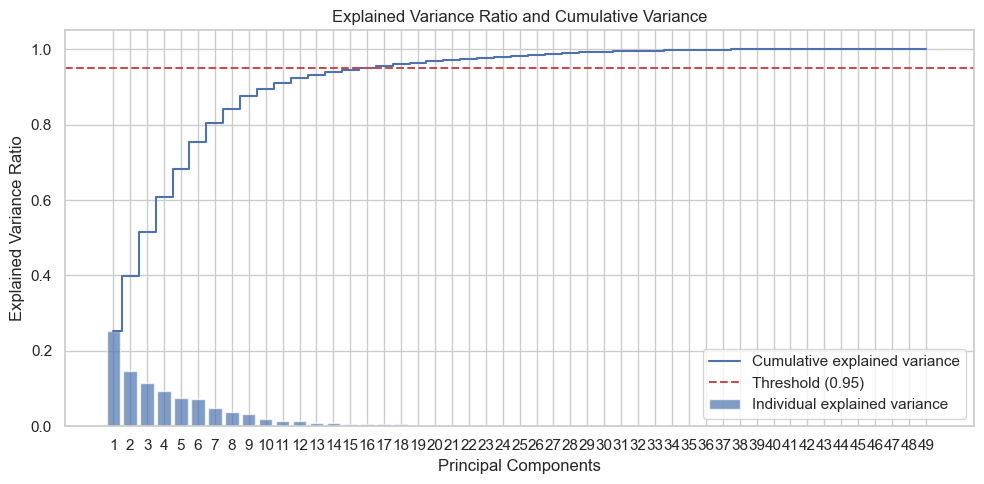

Number of components needed to explain 95.0% variance: 16


In [30]:
# Fit PCA to determine explained variance ratio
pca = PCA(n_components=None)
pca.fit(X)

# Explained variance and cumulative variance
explained_variance_ratio = pca.explained_variance_ratio_
cumulative_variance = np.cumsum(explained_variance_ratio)

# Visualization to determine the optimal number of components
plt.figure(figsize=(10, 5))

# Plot explained variance ratio
plt.bar(range(1, len(explained_variance_ratio) + 1), explained_variance_ratio, alpha=0.7, align='center', label='Individual explained variance')
plt.step(range(1, len(cumulative_variance) + 1), cumulative_variance, where='mid', label='Cumulative explained variance')

# Add thresholds for guidance
threshold = 0.95
plt.axhline(y=threshold, color='r', linestyle='--', label=f'Threshold ({threshold})')

plt.xlabel('Principal Components')
plt.ylabel('Explained Variance Ratio')
plt.title('Explained Variance Ratio and Cumulative Variance')
plt.xticks(range(1, len(explained_variance_ratio) + 1))
plt.legend(loc='best')
plt.tight_layout()
plt.show()

# Determine the number of components to meet the threshold
n_components_needed = np.argmax(cumulative_variance >= threshold) + 1
print(f"Number of components needed to explain {threshold * 100}% variance: {n_components_needed}")

# Refit PCA with the optimal number of components
pca = PCA(n_components=41)
X_reduced = pca.fit_transform(X)

Kode ini digunakan untuk menerapkan Principal Component Analysis (PCA) pada data untuk mengurangi dimensi dengan tetap mempertahankan proporsi besar variabilitas dalam dataset. 

## Split Traning Set and Validation Set

In [17]:
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=42)

### Backward Feature Selection

In [32]:
# features = list(X_train.columns)
# best_features = features.copy()
# history = []

# while len(features) > 1:
#     model = KNeighborsClassifier(n_neighbors=3, metric='euclidean')
#     # Evaluate the model with the current set of features
#     model.fit(X_train[features], y_train)
#     y_pred = model.predict(X_val[features])
#     score = f1_score(y_val, y_pred, average='macro')

#     # Save the current state
#     history.append((features.copy(), score))
#     print(f"Features: {features} | F1 Macro: {score:.4f}")

#     # Identify the least significant feature to remove
#     worst_feature = None
#     worst_score = score

#     for feature in features:
#         reduced_features = [f for f in features if f != feature]
#         model.fit(X_train[reduced_features], y_train)
#         y_pred_reduced = model.predict(X_val[reduced_features])
#         reduced_score = f1_score(y_val, y_pred_reduced, average='macro')

#         # Log the reduced score
#         print(f"Removed feature: {feature} | F1 Macro: {reduced_score:.4f}")

#         if reduced_score > worst_score:
#             worst_score = reduced_score
#             worst_feature = feature

#     # Remove the least significant feature
#     if worst_feature is not None:
#         features.remove(worst_feature)
#         print(f"Removed feature: {worst_feature} | New Features: {features}")
#     else:
#         break

# # Identify the best feature set and score from history
# best_features, best_score = max(history, key=lambda item: item[1])
# print(f"Best Features: {best_features} | Best F1 Macro: {best_score:.4f}")

Kode ini digunakan untuk melakukan seleksi fitur secara iteratif menggunakan metode Backward Feature Elimination (BFE), di mana fitur-fitur dihapus satu per satu berdasarkan dampaknya terhadap performa model. Pendekatan ini memastikan bahwa fitur-fitur yang memiliki kontribusi kecil terhadap performa model dihapus, sehingga menghasilkan subset fitur yang optimal.

## Modeling and Validation

### KNN

In [33]:
from algorithm.knn import KNN

knn = KNN(n_neighbor=3)

knn.fit(X_train, y_train)

y_pred_knn = knn.predict(X_val)

print(f'KNN Accuracy: {accuracy_score(y_val, y_pred_knn)}')
print(f'KNN ROC AUC: {roc_auc_score(y_val, y_pred_knn)}')
print(f"KNN Recall: {recall_score(y_val, y_pred_knn, average='macro')}")
print(f"KNN Precision: {precision_score(y_val, y_pred_knn, average='macro')}")
print(f'KNN F1 Score: {f1_score(y_val, y_pred_knn, average="macro")}')
print(classification_report(y_val, y_pred_knn))

KNN Accuracy: 0.994693921156654
KNN ROC AUC: 0.9694291539048369
KNN Recall: 0.9694291539048367
KNN Precision: 0.9928492591580735
KNN F1 Score: 0.980798744992893
              precision    recall  f1-score   support

           0       0.99      0.94      0.96      2152
           1       1.00      1.00      1.00     25929

    accuracy                           0.99     28081
   macro avg       0.99      0.97      0.98     28081
weighted avg       0.99      0.99      0.99     28081



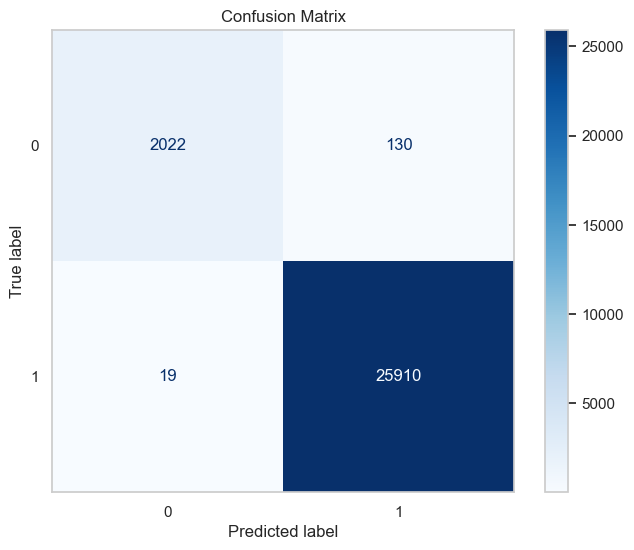

In [34]:
# Generate and visualize the confusion matrix
cm = confusion_matrix(y_val, y_pred_knn)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=np.unique(y_val))

# Plot the confusion matrix
plt.figure(figsize=(8, 6))
disp.plot(cmap=plt.cm.Blues, ax=plt.gca())
plt.grid(False)
plt.title("Confusion Matrix")
plt.show()

In [35]:
from sklearn.neighbors import KNeighborsClassifier

knn = KNeighborsClassifier(n_neighbors=3)

knn.fit(X_train, y_train)

y_pred_knn = knn.predict(X_val)

print(f'KNN Accuracy: {accuracy_score(y_val, y_pred_knn)}')
print(f'KNN ROC AUC: {roc_auc_score(y_val, y_pred_knn)}')
print(f"KNN Recall: {recall_score(y_val, y_pred_knn, average='macro')}")
print(f"KNN Precision: {precision_score(y_val, y_pred_knn, average='macro')}")
print(f'KNN F1 Score: {f1_score(y_val, y_pred_knn, average="macro")}')
print(classification_report(y_val, y_pred_knn))

KNN Accuracy: 0.994693921156654
KNN ROC AUC: 0.9694291539048369
KNN Recall: 0.9694291539048367
KNN Precision: 0.9928492591580735
KNN F1 Score: 0.980798744992893
              precision    recall  f1-score   support

           0       0.99      0.94      0.96      2152
           1       1.00      1.00      1.00     25929

    accuracy                           0.99     28081
   macro avg       0.99      0.97      0.98     28081
weighted avg       0.99      0.99      0.99     28081



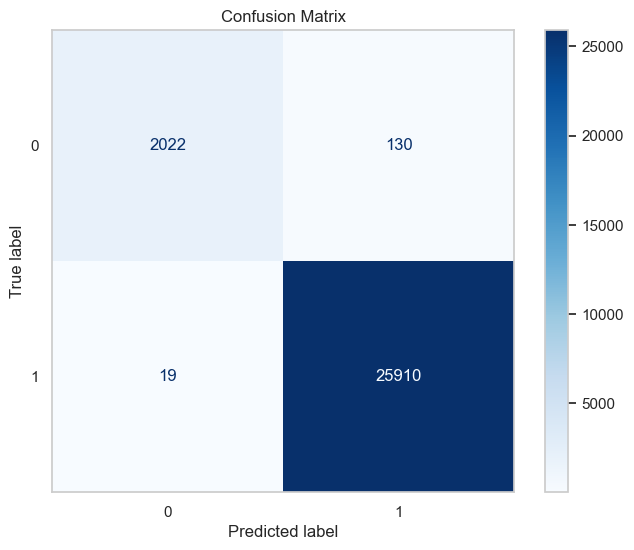

In [36]:
# Generate and visualize the confusion matrix
cm = confusion_matrix(y_val, y_pred_knn)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=np.unique(y_val))

# Plot the confusion matrix
plt.figure(figsize=(8, 6))
disp.plot(cmap=plt.cm.Blues, ax=plt.gca())
plt.grid(False)
plt.title("Confusion Matrix")
plt.show()

### Gaussian Naive Bayes

In [37]:
from algorithm.naive_bayes import GaussianNaiveBayes

gnb = GaussianNaiveBayes()

gnb.fit(X_train, y_train)

y_pred_gnb = gnb.predict(X_val)

print(f'GNB Accuracy: {accuracy_score(y_val, y_pred_gnb)}')
print(f'GNB ROC AUC: {roc_auc_score(y_val, y_pred_gnb)}')
print(f"GNB Recall: {recall_score(y_val, y_pred_gnb, average='macro')}")
print(f"GNB Precision: {precision_score(y_val, y_pred_gnb, average='macro')}")
print(f'GNB F1 Score: {f1_score(y_val, y_pred_gnb, average="macro")}')
print(classification_report(y_val, y_pred_gnb))

GNB Accuracy: 0.9806986930664863
GNB ROC AUC: 0.8779056864032909
GNB Recall: 0.8779056864032909
GNB Precision: 0.9846210965662124
GNB F1 Score: 0.9234713448522472
              precision    recall  f1-score   support

           0       0.99      0.76      0.86      2152
           1       0.98      1.00      0.99     25929

    accuracy                           0.98     28081
   macro avg       0.98      0.88      0.92     28081
weighted avg       0.98      0.98      0.98     28081



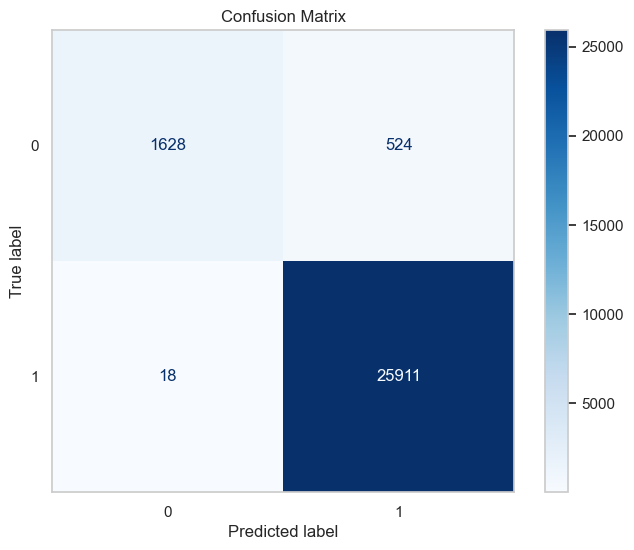

In [38]:
# Generate and visualize the confusion matrix
cm = confusion_matrix(y_val, y_pred_gnb)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=np.unique(y_val))

# Plot the confusion matrix
plt.figure(figsize=(8, 6))
disp.plot(cmap=plt.cm.Blues, ax=plt.gca())
plt.grid(False)
plt.title("Confusion Matrix")
plt.show()

In [39]:
from sklearn.naive_bayes import GaussianNB

gnb = GaussianNB()

gnb.fit(X_train, y_train)

y_pred_gnb = gnb.predict(X_val)

print(f'GNB Accuracy: {accuracy_score(y_val, y_pred_gnb)}')
print(f'GNB ROC AUC: {roc_auc_score(y_val, y_pred_gnb)}')
print(f"GNB Recall: {recall_score(y_val, y_pred_gnb, average='macro')}")
print(f"GNB Precision: {precision_score(y_val, y_pred_gnb, average='macro')}")
print(f'GNB F1 Score: {f1_score(y_val, y_pred_gnb, average="macro")}')
print(classification_report(y_val, y_pred_gnb))

GNB Accuracy: 0.9806986930664863
GNB ROC AUC: 0.8779056864032909
GNB Recall: 0.8779056864032909
GNB Precision: 0.9846210965662124
GNB F1 Score: 0.9234713448522472
              precision    recall  f1-score   support

           0       0.99      0.76      0.86      2152
           1       0.98      1.00      0.99     25929

    accuracy                           0.98     28081
   macro avg       0.98      0.88      0.92     28081
weighted avg       0.98      0.98      0.98     28081



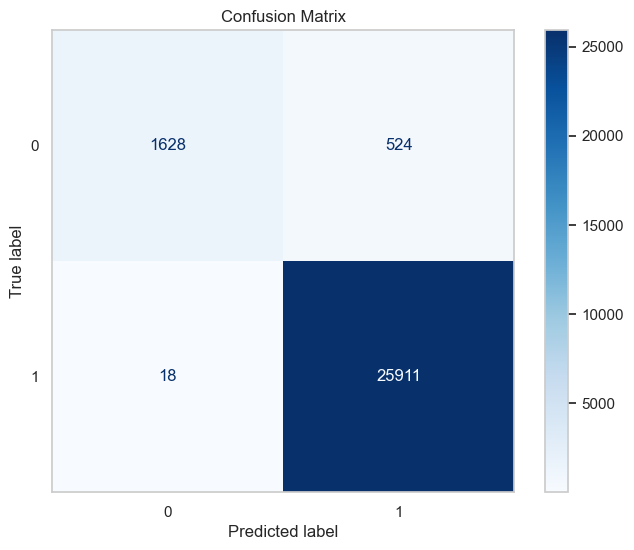

In [40]:
# Generate and visualize the confusion matrix
cm = confusion_matrix(y_val, y_pred_gnb)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=np.unique(y_val))

# Plot the confusion matrix
plt.figure(figsize=(8, 6))
disp.plot(cmap=plt.cm.Blues, ax=plt.gca())
plt.grid(False)
plt.title("Confusion Matrix")
plt.show()

## Hyperparameter Tuning

In [41]:
# Define the hyperparameter grid
param_grid = {
    'n_neighbors': range(1, 11),  # 1 to 10 neighbors
    'metric': ['euclidean', 'manhattan', 'minkowski']  # Distance metrics
}

# Initialize the KNeighborsClassifier
knn = KNeighborsClassifier()

# Use F1 Macro as the scoring metric
scorer = make_scorer(f1_score, average='macro')

# Set up GridSearchCV
grid_search = GridSearchCV(estimator=knn, param_grid=param_grid, scoring=scorer, cv=5, verbose=2, n_jobs=-1)

# Fit the model
grid_search.fit(X, y)

# Get the best model and parameters
best_model = grid_search.best_estimator_
best_params = grid_search.best_params_
best_score = grid_search.best_score_

# Print the best results
print(f"Best Score: {best_score:.4f}")
print(f"Best Parameters: {best_params}")

Fitting 5 folds for each of 30 candidates, totalling 150 fits
Best Score: 0.9841
Best Parameters: {'metric': 'manhattan', 'n_neighbors': 6}


In [18]:
from algorithm.knn import KNN

knn = KNN(n_neighbor=6, metric='manhattan')

knn.fit(X_train, y_train)

y_pred_knn = knn.predict(X_val)

print(f'KNN Accuracy: {accuracy_score(y_val, y_pred_knn)}')
print(f'KNN ROC AUC: {roc_auc_score(y_val, y_pred_knn)}')
print(f"KNN Recall: {recall_score(y_val, y_pred_knn, average='macro')}")
print(f"KNN Precision: {precision_score(y_val, y_pred_knn, average='macro')}")
print(f'KNN F1 Score: {f1_score(y_val, y_pred_knn, average="macro")}')
print(classification_report(y_val, y_pred_knn))

KNN Accuracy: 0.9945870873544389
KNN ROC AUC: 0.9693713036213704
KNN Recall: 0.9693713036213705
KNN Precision: 0.9921219479399592
KNN F1 Score: 0.9804250172080322
              precision    recall  f1-score   support

           0       0.99      0.94      0.96      2152
           1       1.00      1.00      1.00     25929

    accuracy                           0.99     28081
   macro avg       0.99      0.97      0.98     28081
weighted avg       0.99      0.99      0.99     28081



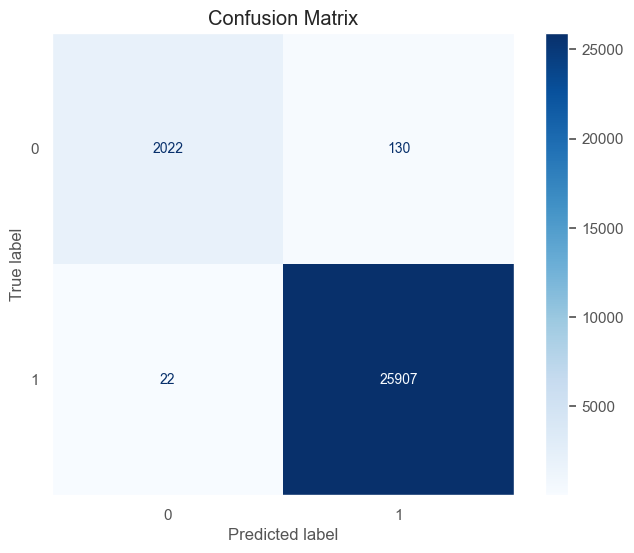

In [21]:
# Generate and visualize the confusion matrix
cm = confusion_matrix(y_val, y_pred_knn)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=np.unique(y_val))

# Plot the confusion matrix
plt.figure(figsize=(8, 6))
disp.plot(cmap=plt.cm.Blues, ax=plt.gca())
plt.grid(False)
plt.title("Confusion Matrix")
plt.show()

In [42]:
# Definisikan parameter untuk grid search
param_grid = {
    'var_smoothing': [1e-9, 1e-8, 1e-7, 1e-6, 1e-5, 1e-4, 1e-3, 1e-2, 1e-1, 1]
}

# Inisialisasi model GaussianNB
gnb = GaussianNB()

# Grid search dengan cross-validation
grid_search = GridSearchCV(estimator=gnb, param_grid=param_grid, scoring='f1_macro', cv=5)
grid_search.fit(X, y)

# Output hasil terbaik
print(f"Best parameters: {grid_search.best_params_}")
print(f"Best F1-Score: {grid_search.best_score_}")


Best parameters: {'var_smoothing': 0.001}
Best F1-Score: 0.9781018412192266


In [19]:
from algorithm.naive_bayes import GaussianNaiveBayes

gnb = GaussianNaiveBayes(var_smoothing=0.001)

gnb.fit(X_train, y_train)

y_pred_gnb = gnb.predict(X_val)

print(f'GNB Accuracy: {accuracy_score(y_val, y_pred_gnb)}')
print(f'GNB ROC AUC: {roc_auc_score(y_val, y_pred_gnb)}')
print(f"GNB Recall: {recall_score(y_val, y_pred_gnb, average='macro')}")
print(f"GNB Precision: {precision_score(y_val, y_pred_gnb, average='macro')}")
print(f'GNB F1 Score: {f1_score(y_val, y_pred_gnb, average="macro")}')
print(classification_report(y_val, y_pred_gnb))

GNB Accuracy: 0.9932694704604537
GNB ROC AUC: 0.9633313523016311
GNB Recall: 0.9633313523016312
GNB Precision: 0.9886546910601606
GNB F1 Score: 0.9755905165493355
              precision    recall  f1-score   support

           0       0.98      0.93      0.95      2152
           1       0.99      1.00      1.00     25929

    accuracy                           0.99     28081
   macro avg       0.99      0.96      0.98     28081
weighted avg       0.99      0.99      0.99     28081



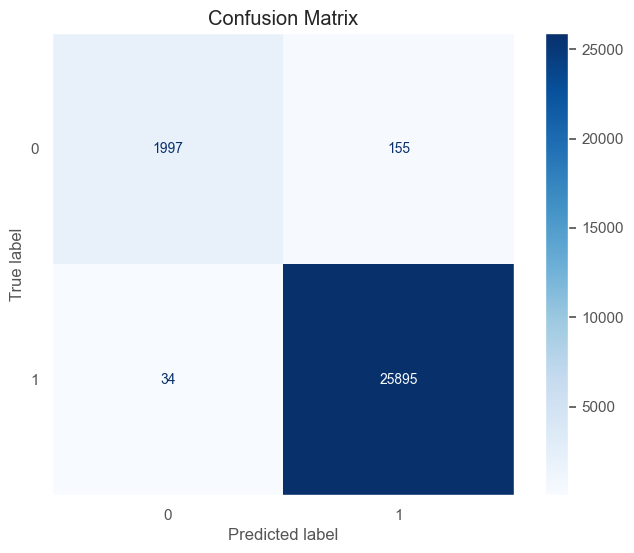

In [22]:
# Generate and visualize the confusion matrix
cm = confusion_matrix(y_val, y_pred_gnb)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=np.unique(y_val))

# Plot the confusion matrix
plt.figure(figsize=(8, 6))
disp.plot(cmap=plt.cm.Blues, ax=plt.gca())
plt.grid(False)
plt.title("Confusion Matrix")
plt.show()

## Submission

In [43]:
from algorithm.naive_bayes import GaussianNaiveBayes

gnb =  GaussianNaiveBayes(var_smoothing=0.01)

gnb.fit(X, y)

y_pred_gnb = gnb.predict(df_test)

sample_submission['label'] = y_pred_gnb

sample_submission.to_csv('best_submission_gnb.csv', index=False)

In [44]:
from algorithm.knn import KNN

knn = KNN(n_neighbor=6, metric='manhattan')

knn.fit(X, y)

y_pred_knn = knn.predict(df_test)

sample_submission['label'] = y_pred_knn

sample_submission.to_csv('best_submission_knn.csv', index=False)

## Save Model and Pipeline

In [23]:
# Save the model
joblib.dump(knn, 'knn_model.pkl')  # Menyimpan model KNN
joblib.dump(gnb, 'gnb_model.pkl')  # Menyimpan model GNB
joblib.dump(pipeline, 'pipeline.pkl')   # Menyimpan pipeline

# Load the model
loaded_model_knn = joblib.load('knn_model.pkl')
loaded_model_gnb = joblib.load('gnb_model.pkl')
loaded_pipeline = joblib.load('pipeline.pkl')

## Error Analysis

Model KNN memiliki performa lebih baik dibandingkan GNB dengan F1-score makro 0.980 versus 0.933. Precision dan Recall untuk KNN juga lebih tinggi dibandingkan GNB, menunjukkan bahwa KNN lebih akurat dalam memprediksi kedua kelas.

KNN memiliki precision sebesar 99% dan recall sebesar 94% untuk kelas 0, sementara GNB hanya mencapai precision 98% dan recall 79%. Hal ini menunjukkan bahwa KNN lebih unggul dalam mendeteksi kelas 0 tanpa mengorbankan prediksi untuk kelas mayoritas.
Gaussian Naive Bayes cenderung melakukan lebih banyak kesalahan pada kelas 0 dengan memprediksinya sebagai kelas 1 (false negative). Hal ini kemungkinan disebabkan oleh asumsi distribusi Gaussian yang tidak sepenuhnya cocok untuk dataset ini.

Dataset memiliki ketidakseimbangan kelas (kelas 1 jauh lebih banyak daripada kelas 0). KNN mampu menangani ketidakseimbangan ini dengan lebih baik karena pendekatannya yang berbasis jarak dan mempertimbangkan tetangga terdekat.
GNB, di sisi lain, lebih rentan terhadap ketidakseimbangan kelas karena perhitungannya didasarkan pada probabilitas dan asumsi distribusi yang ideal.

